# 03. Kết quả và thảo luận
Mọi con số dưới đây được tính lại từ `runs.csv`, `runs_A.csv`; giả thuyết H1–H4 là để kiểm chứng, không phải kết luận có sẵn.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", None, "display.width", 200, "display.max_colwidth", 120)
from src.config import PATHS, load_config
from IPython.display import Image, display
from scipy.stats import spearmanr
from src.experiments.analyze import b1_vs_b2, bfs_report, expansion_scaling, gbfs_gap_vs_detour, summary

df = pd.read_csv(PATHS.TABLES / "runs.csv")
named = ["C1", "C2", "C3", "C3b", "C4", "C5a", "C5b", "C5c"]
pivot = df.pivot_table(index=["dataset", "case_id"], columns="algorithm", values="expanded")
gaps = df.pivot_table(index=["dataset", "case_id"], columns="algorithm", values="gap_pct")
display(summary(df))

,dataset,algorithm,n_cases,expanded_mean,expanded_median,expanded_ratio_to_ucs_median,gap_pct_median,gap_pct_max,optimal_pct,runtime_ms_median
0,B1,BFS,56,22877.518,21501.0,1.324,32.202,122.077,5.357,11.317
1,B1,GBFS,56,311.821,145.5,0.010,33.981,73.047,5.357,0.296
2,B1,ASTAR,56,2723.268,1891.5,0.145,0.000,0.000,100.000,3.782
3,B1,UCS,56,17228.482,17650.0,1.000,0.000,0.000,100.000,25.183
4,B2,BFS,31,1805.323,1742.0,1.219,20.570,123.911,12.903,0.669
5,B2,GBFS,31,108.032,71.0,0.057,28.859,109.389,9.677,0.139
6,B2,ASTAR,31,443.613,268.0,0.212,0.000,0.000,100.000,0.428
7,B2,UCS,31,1620.355,1513.0,1.000,0.000,0.000,100.000,1.561


## RQ1. A\* có luôn tối ưu không, và tiết kiệm bao nhiêu?
**H1:** `gap_pct(A*) = 0` ở mọi ca; `expanded(A*) ≤ expanded(UCS)`.

Số ca: 87
max gap(A*) = 0.0 %
Số ca expanded(A*) > expanded(UCS): 0
Tổng reopened của A*: 0
H1: ĐẠT


,A*/UCS,A*/BFS
trung vị theo đồ thị,,
B1,0.145,0.100
B2,0.212,0.182


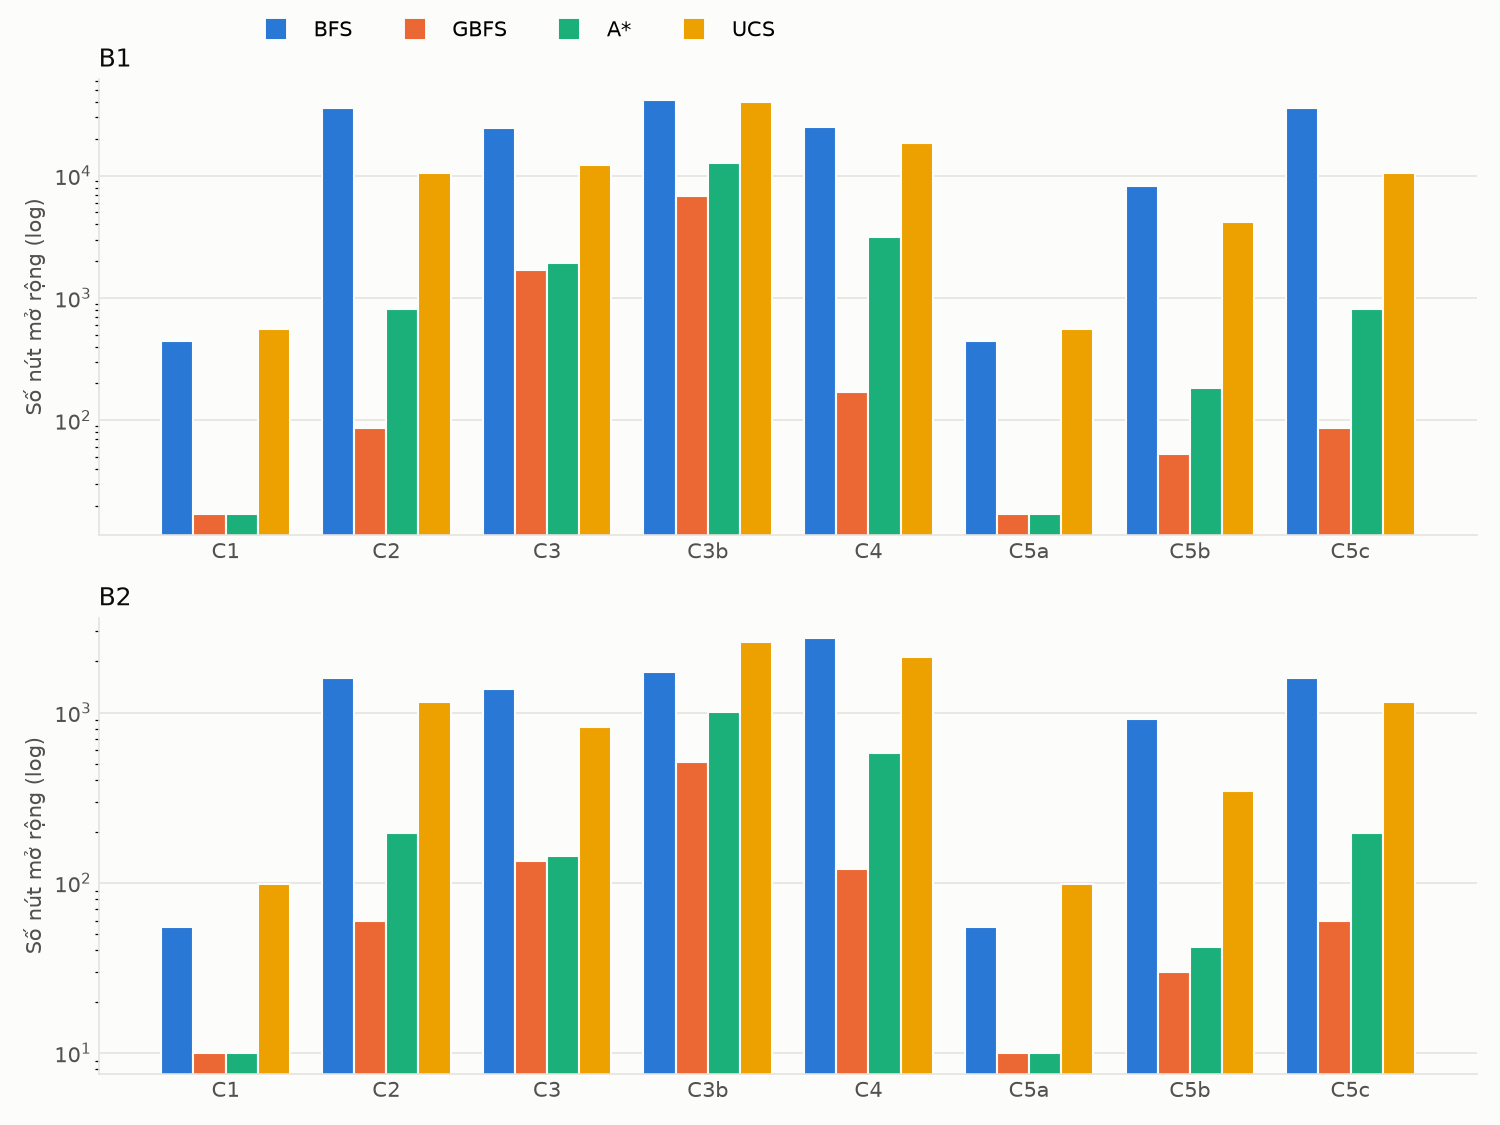

In [2]:
print("Số ca:", len(pivot))
print("max gap(A*) =", gaps["ASTAR"].abs().max(), "%")
print("Số ca expanded(A*) > expanded(UCS):", int((pivot["ASTAR"] > pivot["UCS"]).sum()))
print("Tổng reopened của A*:", int(df.loc[df.algorithm == "ASTAR", "reopened"].sum()))
print("H1:", "ĐẠT" if gaps["ASTAR"].abs().max() < 1e-6 and (pivot["ASTAR"] <= pivot["UCS"]).all() else "KHÔNG ĐẠT")
saving = pd.DataFrame({"A*/UCS": pivot["ASTAR"] / pivot["UCS"], "A*/BFS": pivot["ASTAR"] / pivot["BFS"]})
display(saving.groupby("dataset").median().round(3).rename_axis("trung vị theo đồ thị"))
display(Image(PATHS.FIGURES / "fig_expanded_by_case.png", width=720))

## RQ2. GBFS nhanh hơn bao nhiêu và mất tối ưu bao nhiêu?
**H2:** GBFS có `expanded` nhỏ nhất ở phần lớn ca; `gap_pct(GBFS)` tăng theo `detour`.

GBFS có expanded nhỏ nhất (kể cả hòa) ở 98.9% số ca


,count,mean,std,min,25%,50%,75%,max
dataset,,,,,,,,
B1,56.0,33.50,18.97,0.0,17.25,33.98,47.39,73.05
B2,31.0,28.15,25.26,0.0,6.55,28.86,36.50,109.39


,dataset,n,spearman_rho,p_value
0,B1,54,0.371,0.0058
1,B2,29,0.258,0.1759


Nhóm ngẫu nhiên, bỏ các đích bị chọn tự động có detour cực lớn:
  B1: rho = 0.248, p = 0.0892, n = 48
  B2: rho = -0.025, p = 0.9109, n = 23


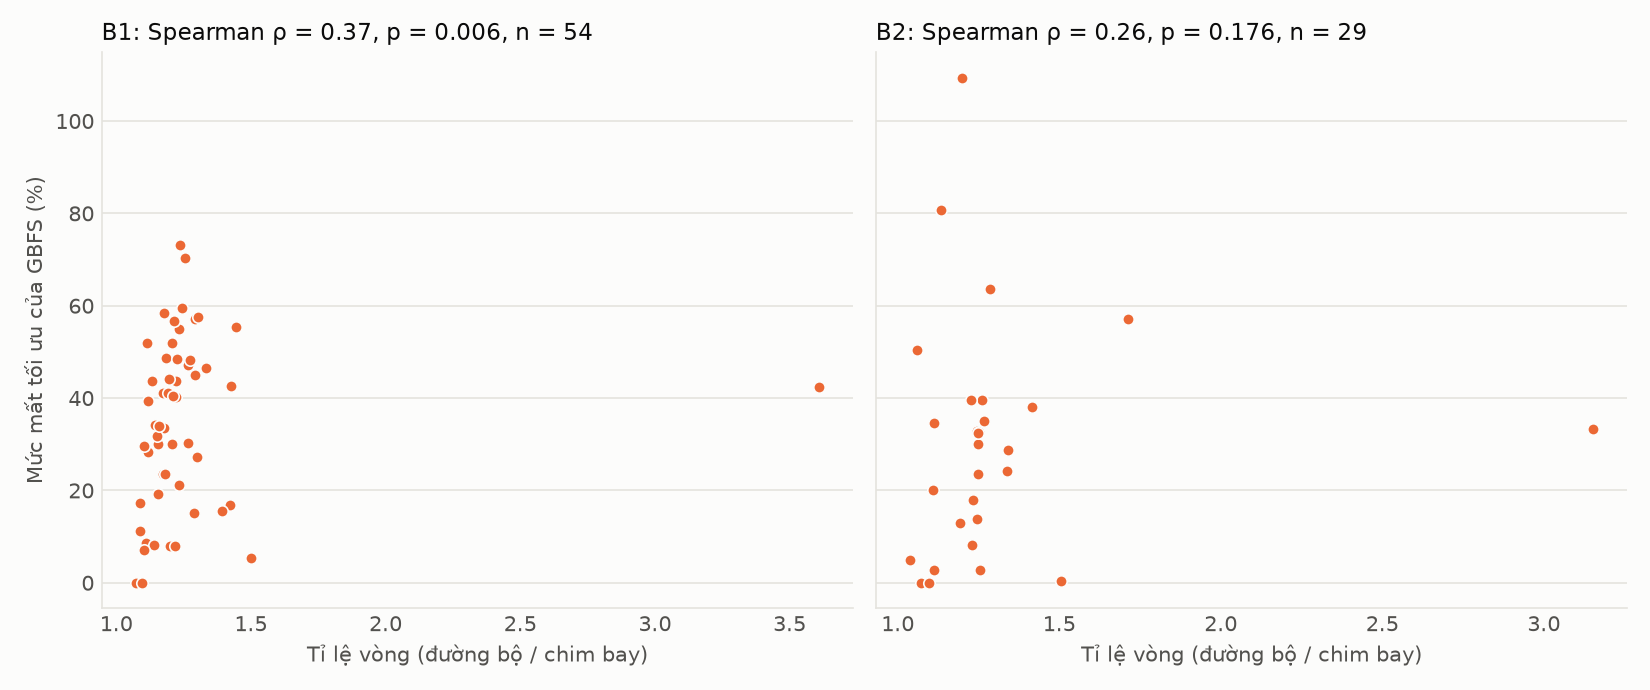

In [3]:
smallest = pivot["GBFS"] <= pivot[["BFS", "ASTAR", "UCS"]].min(axis=1)
print(f"GBFS có expanded nhỏ nhất (kể cả hòa) ở {smallest.mean():.1%} số ca")
display((gaps["GBFS"].groupby("dataset").describe()).round(2))
display(gbfs_gap_vs_detour(df))
print("Nhóm ngẫu nhiên, bỏ các đích bị chọn tự động có detour cực lớn:")
for dataset, group in df[(df.algorithm == "GBFS") & (df.property == "random")].groupby("dataset"):
    result = spearmanr(group["detour"], group["gap_pct"])
    print(f"  {dataset}: rho = {result.statistic:.3f}, p = {result.pvalue:.4f}, n = {len(group)}")
display(Image(PATHS.FIGURES / "fig_gbfs_gap_vs_detour.png", width=720))

## RQ3. Đường của BFS dài hơn đường tối ưu bao nhiêu?
**H3:** `gap_pct(BFS) > 0` ở phần lớn ca; lớn nhất ở C4.

Tỉ lệ ca có gap(BFS) > 0: 92.0%


,dataset,group,n,hops_bfs,hops_ucs,km_bfs,km_ucs,gap_pct
0,B1,C4,1,54.0,115.0,18.457,12.616,46.296
1,B1,random (trung vị),48,49.5,101.0,17.558,12.441,34.792
2,B2,C4,1,40.0,63.0,15.146,12.429,21.860
3,B2,random (trung vị),23,36.0,51.0,15.083,12.877,20.581


B1: gap(BFS) lớn nhất toàn bộ 122.1% ở R26; trong các ca có tên 59.5% ở C3b; C4 = 46.3%
B2: gap(BFS) lớn nhất toàn bộ 123.9% ở R14; trong các ca có tên 30.5% ở C5b; C4 = 21.9%


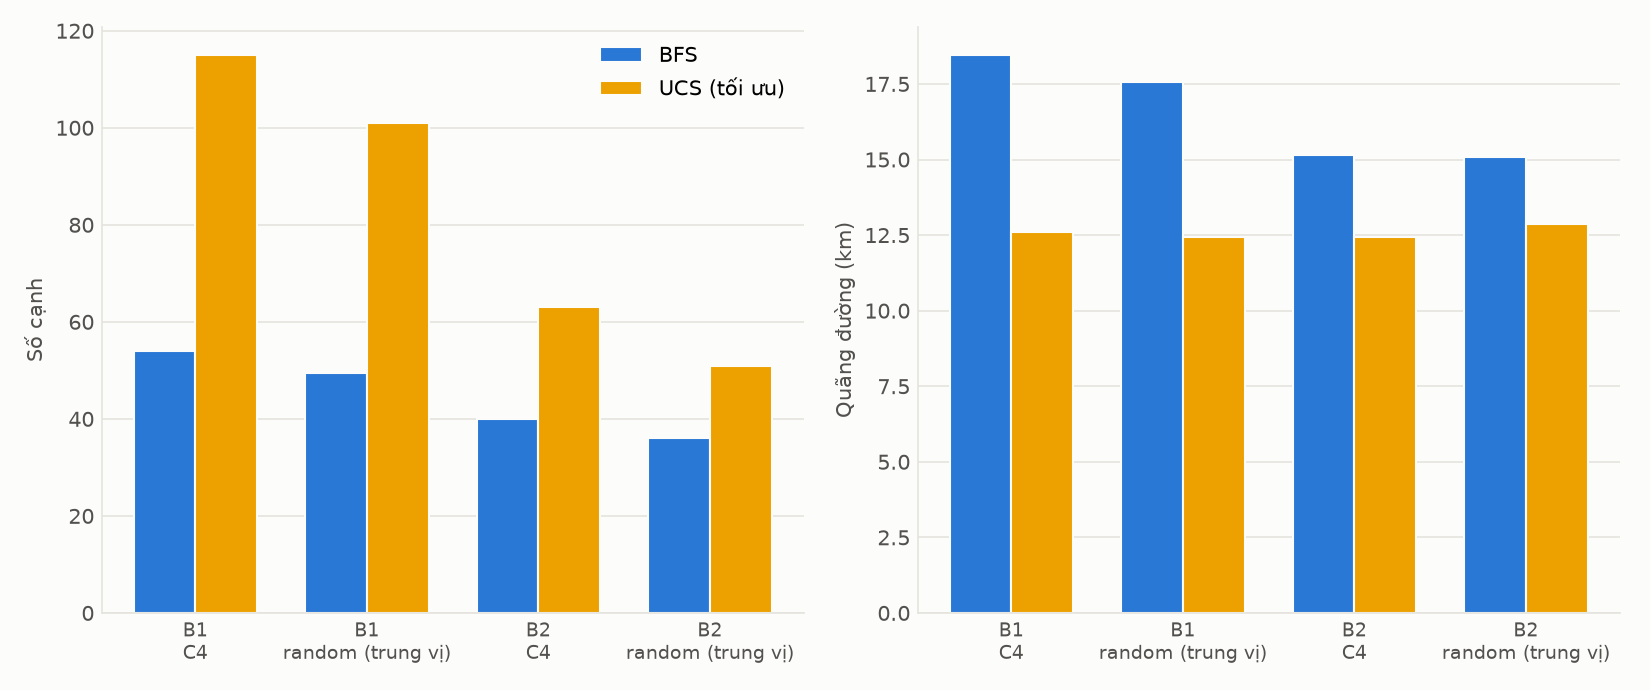

In [4]:
print(f"Tỉ lệ ca có gap(BFS) > 0: {(gaps['BFS'] > 1e-6).mean():.1%}")
display(bfs_report(df))
for dataset in ["B1", "B2"]:
    series = gaps.loc[dataset, "BFS"]
    among_named = series.reindex(named)
    print(f"{dataset}: gap(BFS) lớn nhất toàn bộ {series.max():.1f}% ở {series.idxmax()}; trong các ca có tên {among_named.max():.1f}% ở {among_named.idxmax()}; C4 = {series['C4']:.1f}%")
display(Image(PATHS.FIGURES / "fig_bfs_hops_vs_km.png", width=720))

## RQ4. Khoảng cách và độ chi tiết của bản đồ
**H4:** `expanded` tăng theo khoảng cách; BFS và UCS tăng nhanh hơn A\* (hệ số góc log–log lớn hơn); `expanded` trên B1 lớn hơn nhiều so với B2.

,dataset,algorithm,n,slope,r2
0,B1,BFS,51,1.624,0.677
1,B1,GBFS,51,1.173,0.752
2,B1,ASTAR,51,2.047,0.822
3,B1,UCS,51,1.663,0.971
4,B2,BFS,26,1.728,0.881
5,B2,GBFS,26,1.152,0.715
6,B2,ASTAR,26,1.815,0.788
7,B2,UCS,26,1.648,0.972


BFS và UCS có hệ số góc lớn hơn A*: {'B1': False, 'B2': False}


,algorithm,n_pairs,expanded_b1_median,expanded_b2_median,ratio_b1_b2
0,BFS,23,17768.0,2210.0,8.04
1,GBFS,23,146.0,77.0,1.90
2,ASTAR,23,2366.0,424.0,5.58
3,UCS,23,17361.0,2209.0,7.86


algorithm                    ASTAR      BFS  GBFS      UCS
dataset case_id d_euclid_m                                
B1      C5a     1687.513088   17.0    448.0  17.0    552.0
        C5b     4613.143673  184.0   8230.0  53.0   4187.0
        C5c     7770.550700  805.0  36113.0  87.0  10612.0
B2      C5a     1687.513088   10.0     55.0  10.0     99.0
        C5b     4626.346629   42.0    919.0  30.0    344.0
        C5c     7770.550700  197.0   1591.0  60.0   1150.0

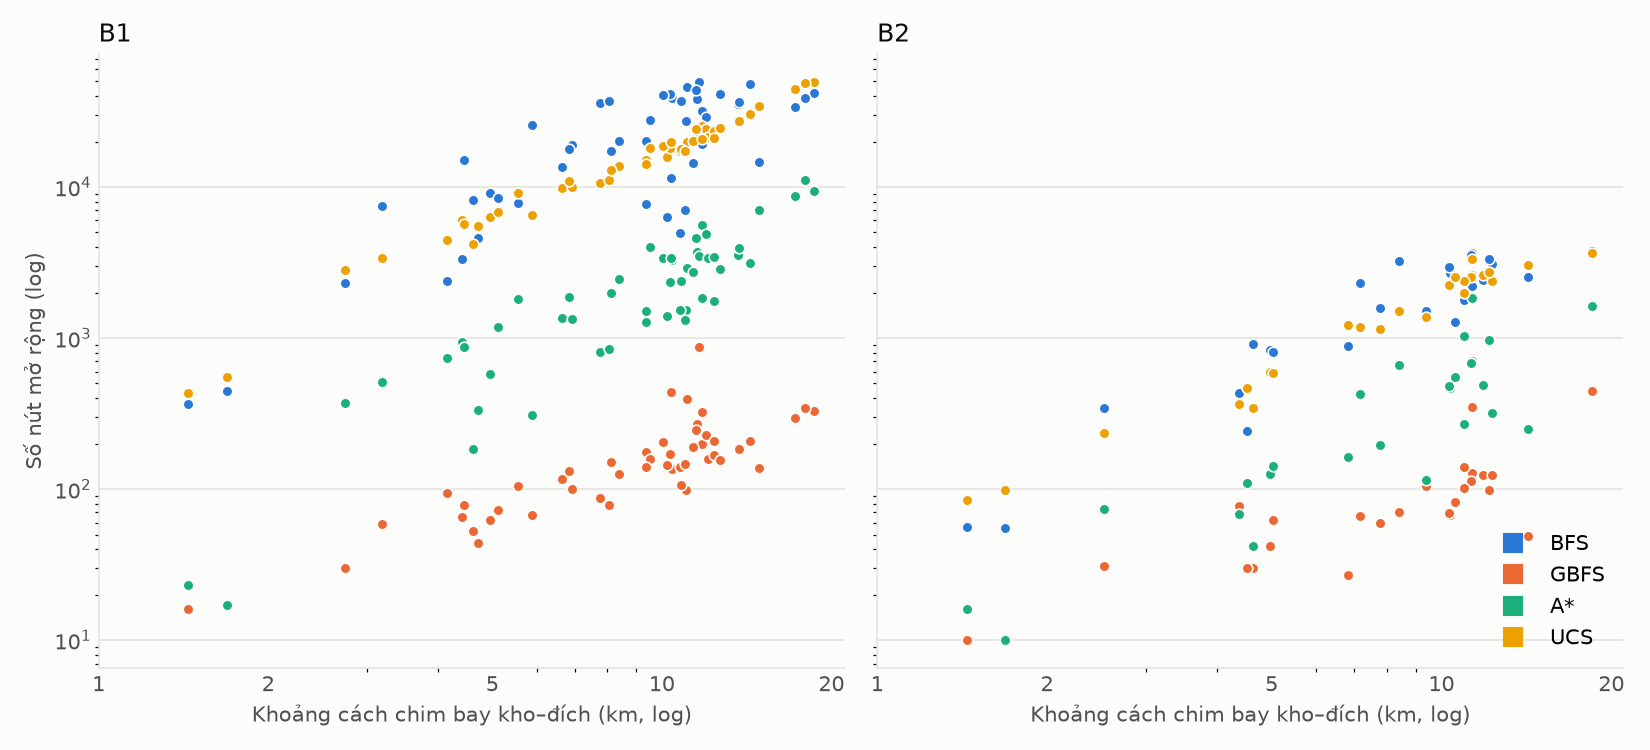

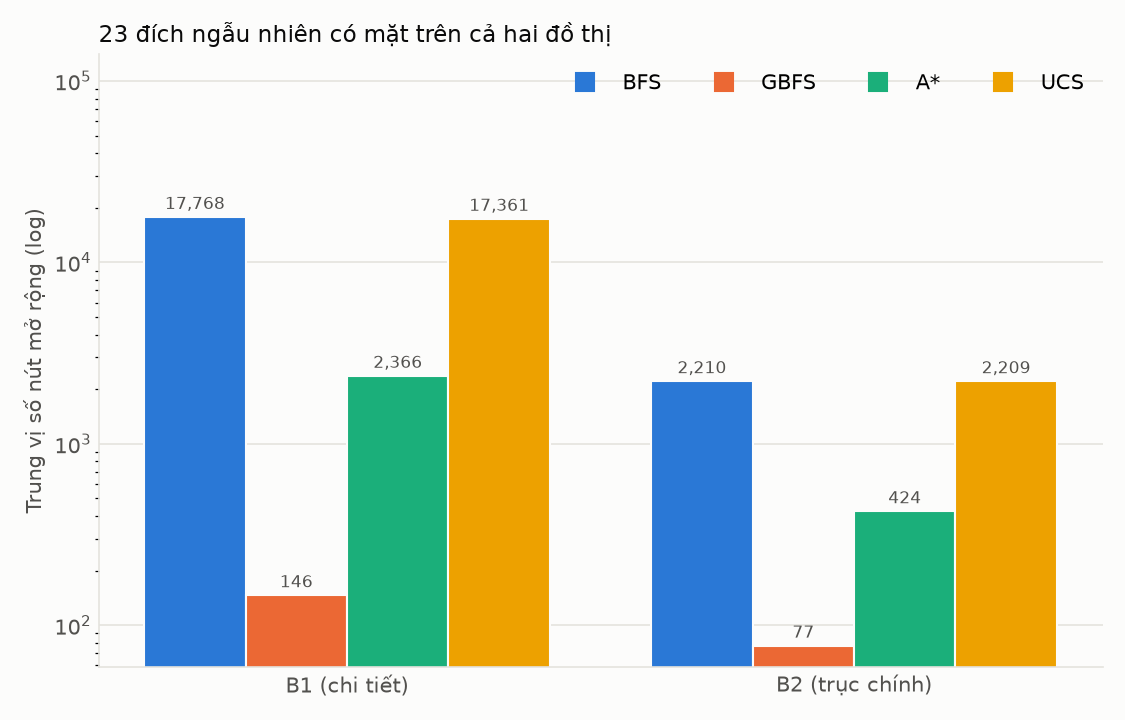

In [5]:
slopes = expansion_scaling(df)
display(slopes)
wide = slopes.pivot(index="dataset", columns="algorithm", values="slope")
print("BFS và UCS có hệ số góc lớn hơn A*:", ((wide["BFS"] > wide["ASTAR"]) & (wide["UCS"] > wide["ASTAR"])).to_dict())
display(b1_vs_b2(df))
display(df[df.case_id.isin(["C5a", "C5b", "C5c"])].pivot_table(index=["dataset", "case_id", "d_euclid_m"], columns="algorithm", values="expanded").round(0))
display(Image(PATHS.FIGURES / "fig_expanded_vs_distance.png", width=720))
display(Image(PATHS.FIGURES / "fig_b1_vs_b2.png", width=560))

## Hình dạng vùng mở rộng
Kỳ vọng: BFS và UCS loang rộng quanh kho; A\* thon dài về phía đích; GBFS hẹp nhưng có thể lạc hướng khi gặp vật cản.

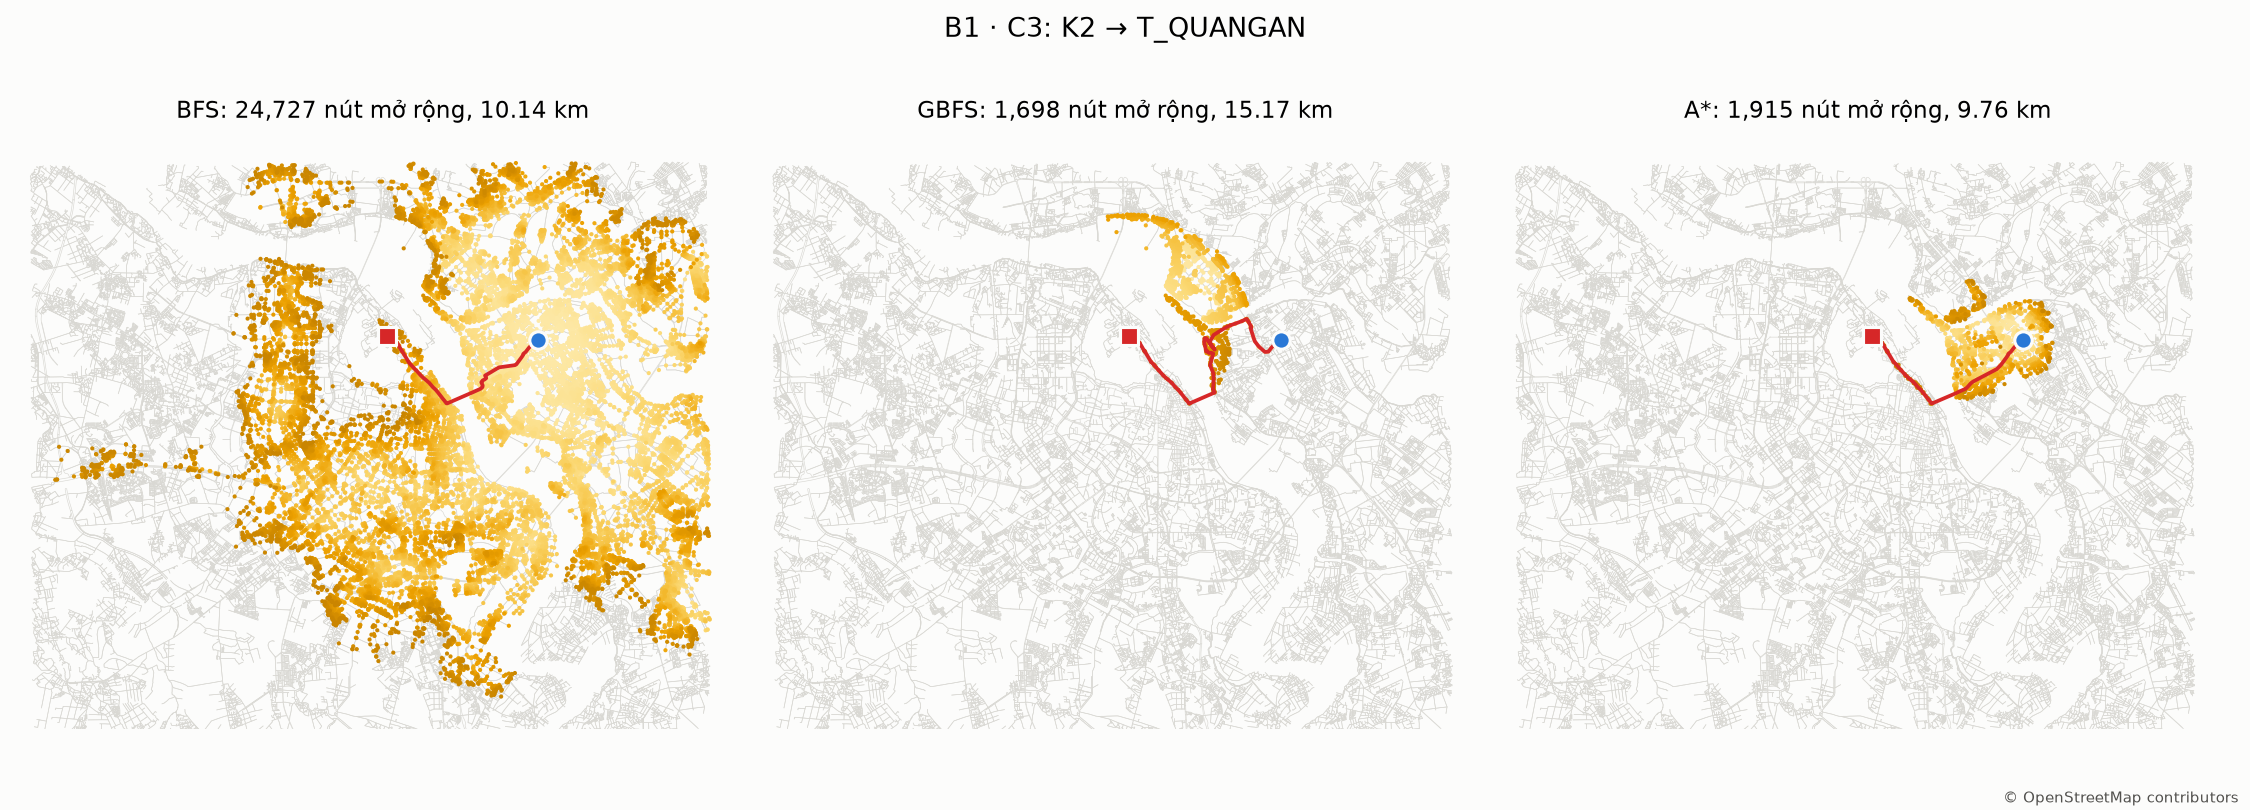

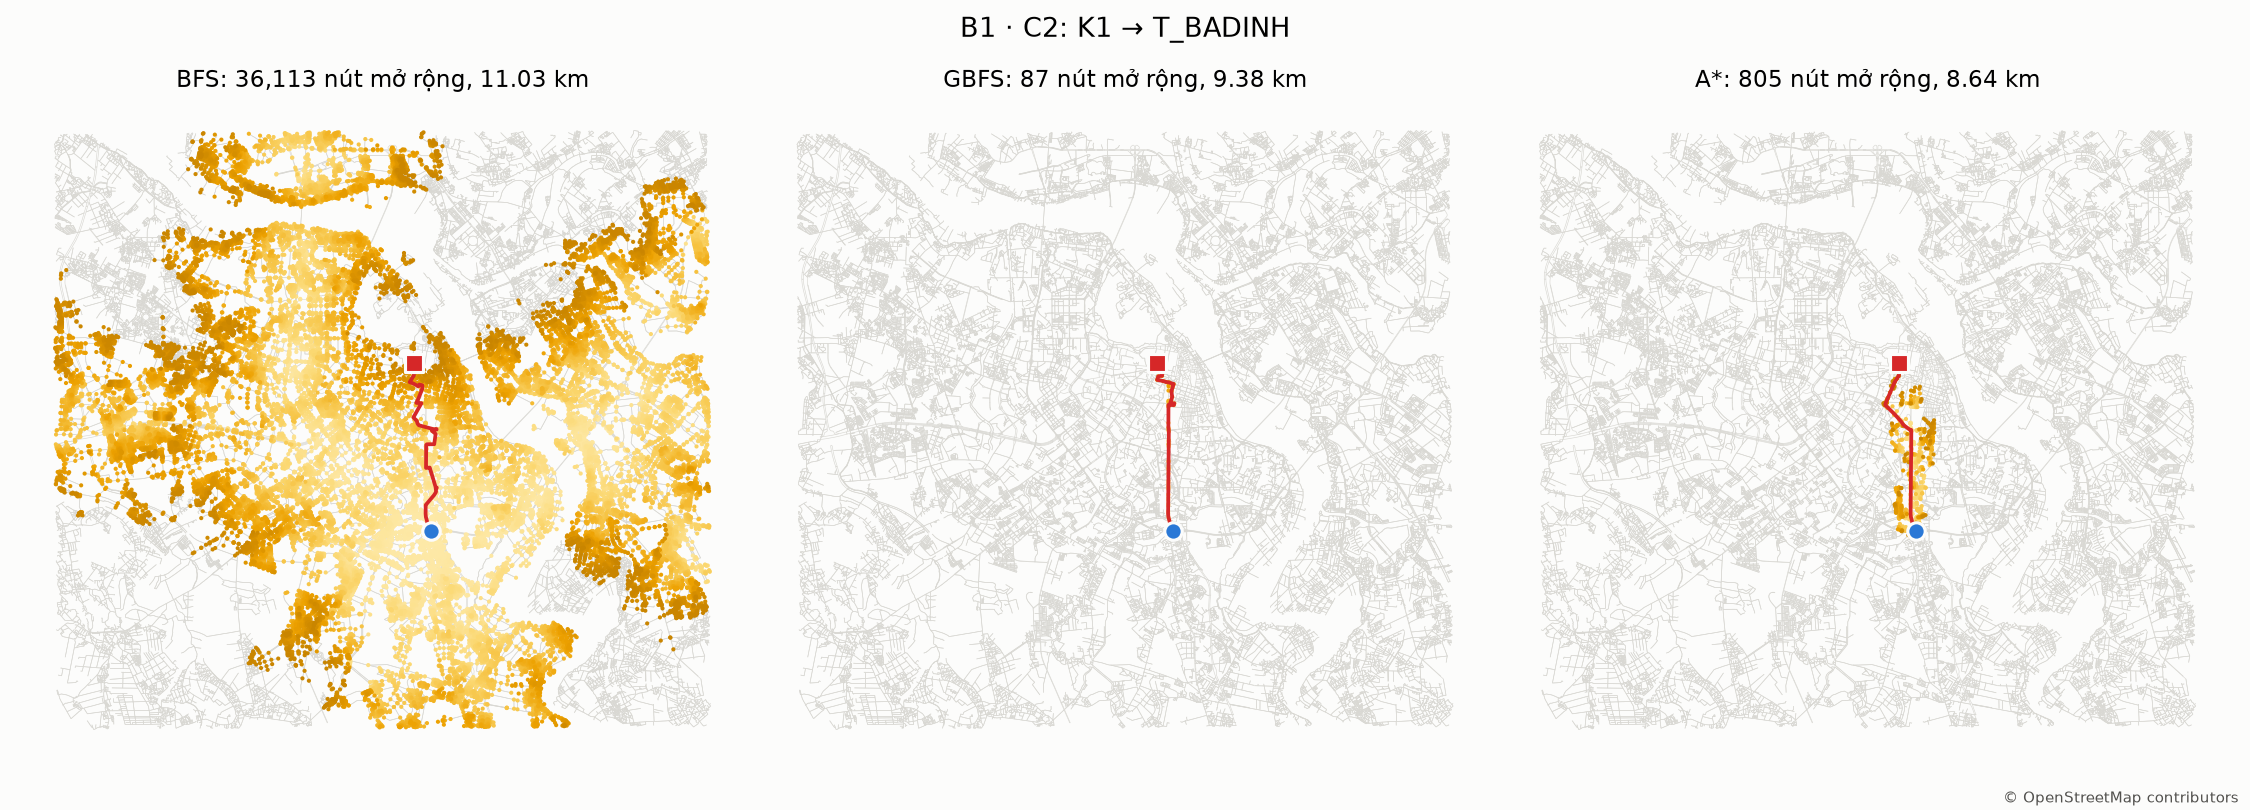

In [6]:
display(Image(PATHS.FIGURES / "fig_expansions_B1_C3.png", width=900))
display(Image(PATHS.FIGURES / "fig_expansions_B1_C2.png", width=900))

## Mức A và kịch bản nhiều điểm dừng

In [7]:
runs_a = pd.read_csv(PATHS.TABLES / "runs_A.csv")
display(summary(runs_a))
display(pd.read_csv(PATHS.TABLES / "multistop.csv"))

,dataset,algorithm,n_cases,expanded_mean,expanded_median,expanded_ratio_to_ucs_median,gap_pct_median,gap_pct_max,optimal_pct,runtime_ms_median
0,A,BFS,132,7.000,7.0,1.000,0.0,0.000,100.000,0.004
1,A,GBFS,132,3.606,3.0,0.500,0.0,38.298,83.333,0.005
2,A,ASTAR,132,4.447,4.0,0.667,0.0,0.000,100.000,0.006
3,A,UCS,132,7.000,7.0,1.000,0.0,0.000,100.000,0.008


,scenario,dataset,order_rule,order,total_m,total_expanded_astar,total_expanded_ucs
0,M1,B1,euclid,K1 → T_GIAPBAT → T_BACHKHOA → T_BADINH → T_PHUTAYHO → T_MYDINH,42558.53,7314,49282
1,M1,B1,road,K1 → T_GIAPBAT → T_BACHKHOA → T_BADINH → T_PHUTAYHO → T_MYDINH,42558.53,7314,49282
2,M1,B2,euclid,K1 → T_GIAPBAT → T_BACHKHOA → T_BADINH → T_PHUTAYHO → T_MYDINH,35364.90,917,5074
3,M1,B2,road,K1 → T_GIAPBAT → T_BACHKHOA → T_BADINH → T_PHUTAYHO → T_MYDINH,35364.90,917,5074
